## EDA on COVID-19 

- Data Explore spread patterns, recovery rates, and trends over time.

- Bar chart of sales by region
- Pie chart of product categories
- Line chart showing monthly revenue trends


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv("data_base/covid-data.csv")

df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("Dataset shape:", df.shape)
print(df.head())
print(df.columns.tolist())

Dataset shape: (429435, 67)
  iso_code continent     location       date  total_cases  new_cases  \
0      AFG      Asia  Afghanistan 2020-01-05          0.0        0.0   
1      AFG      Asia  Afghanistan 2020-01-06          0.0        0.0   
2      AFG      Asia  Afghanistan 2020-01-07          0.0        0.0   
3      AFG      Asia  Afghanistan 2020-01-08          0.0        0.0   
4      AFG      Asia  Afghanistan 2020-01-09          0.0        0.0   

   new_cases_smoothed  total_deaths  new_deaths  new_deaths_smoothed  ...  \
0                 NaN           0.0         0.0                  NaN  ...   
1                 NaN           0.0         0.0                  NaN  ...   
2                 NaN           0.0         0.0                  NaN  ...   
3                 NaN           0.0         0.0                  NaN  ...   
4                 NaN           0.0         0.0                  NaN  ...   

   male_smokers  handwashing_facilities  hospital_beds_per_thousand  \
0    

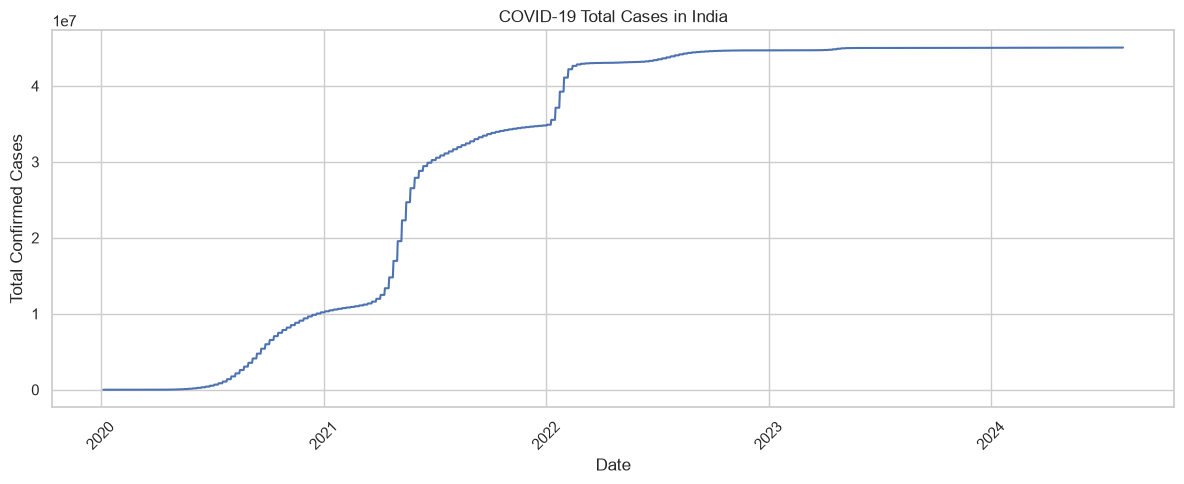

In [5]:
india = df[df["location"] == "India"].copy()
india = india.sort_values("date")

plt.figure(figsize=(12, 5))
plt.plot(india["date"], india["total_cases"])
plt.title("COVID-19 Total Cases in India")
plt.xlabel("Date")
plt.ylabel("Total Confirmed Cases")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

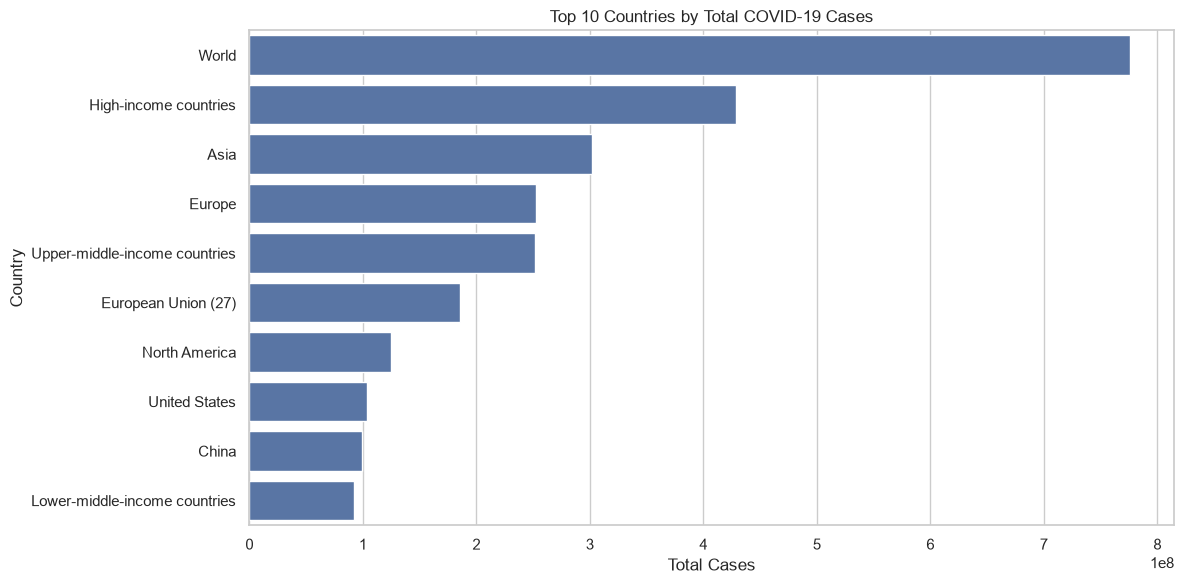

In [7]:
latest = df.dropna(subset=["total_cases"])
latest = latest.sort_values("date")
latest = latest.groupby("location").tail(1)

top10 = latest.nlargest(10, "total_cases")

plt.figure(figsize=(12, 6))
sns.barplot(data=top10, x="total_cases", y="location")
plt.title("Top 10 Countries by Total COVID-19 Cases")
plt.xlabel("Total Cases")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

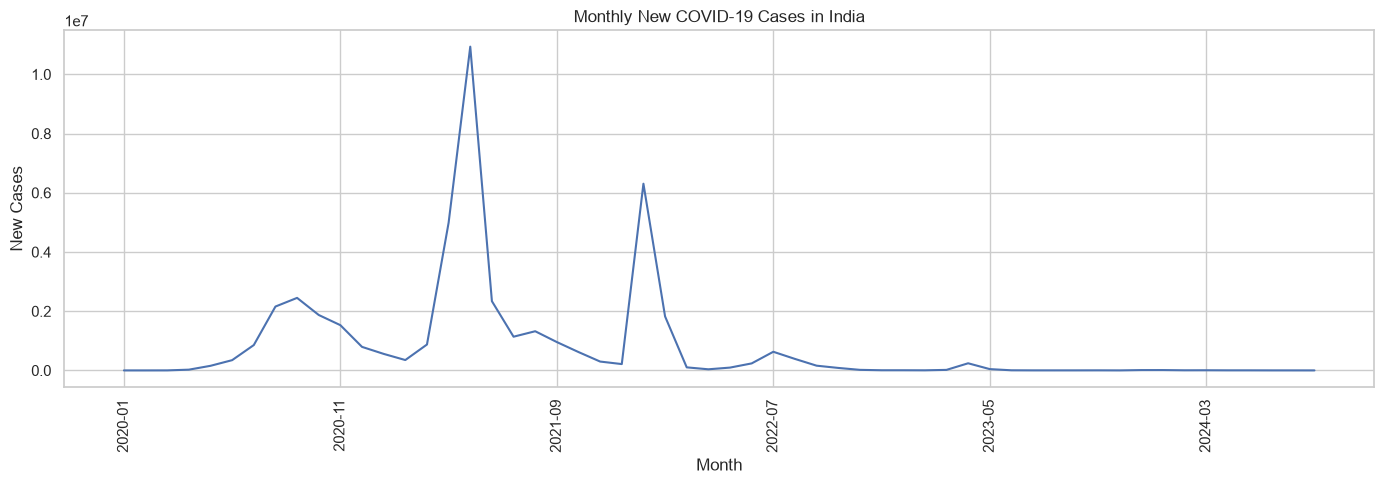

In [8]:
india = india.dropna(subset=["new_cases"]).copy()
india["month"] = india["date"].dt.to_period("M")

monthly = india.groupby("month")["new_cases"].sum()
monthly.index = monthly.index.astype(str)

plt.figure(figsize=(14, 5))
monthly.plot()
plt.title("Monthly New COVID-19 Cases in India")
plt.xlabel("Month")
plt.ylabel("New Cases")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()